# B0 — Majority, inertia and Markov

Workstream 1. CPU experiments on the three native label spaces. Training is reproducible via `scripts/train_b0.py`; this executed notebook audits and explains saved results. Gold-history variants are **oracle references**, not headline models.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from emotionshift.data.loaders import load
from emotionshift.data.labels import emotions
from emotionshift.models.b0 import HistoryBaselines

## Data contract
EmoWOZ retains native classes; only labelled user turns are scored. DailyDialog headline uses test_dedup; test is secondary.

In [2]:
counts = []
for dataset in ['meld', 'dailydialog', 'emowoz']:
    frame = load(dataset)
    targets = frame[frame.emotion.notna()]
    for split, group in targets.groupby('split'):
        counts.append({'dataset': dataset, 'split': split, 'targets': len(group)})
display(pd.DataFrame(counts))

,dataset,split,targets
0,meld,dev,1109
1,meld,test,2610
2,meld,train,9989
3,dailydialog,dev,8069
4,dailydialog,test,7740
5,dailydialog,test_dedup,7019
6,dailydialog,train,87170
7,emowoz,dev,8509
8,emowoz,test,8634
9,emowoz,train,66474


## Baseline rules
The donor is the supporting utterance-only SVM. Inertia copies its **previous** prediction for the same speaker. Markov reads only that historical label and train transitions. The first turn uses train majority. Recursive self-copying would never change class.

In [3]:
df = load('meld')
train = df[df.split == 'train']
test = df[df.split == 'test'].copy()
path = 'predictions/b0_donor_meld_test_seed0.csv'
donor = pd.Series(pd.read_csv(path).pred.to_numpy(), index=test.index)
b0 = HistoryBaselines(emotions('meld')).fit(train)
predictions = b0.predict(test.drop(columns=['emotion', 'prev_emotion']), donor)
display(pd.concat([test[['dialogue_id', 'turn', 'speaker', 'text']], predictions], axis=1).head(8))

,dialogue_id,turn,speaker,text,majority,inertia_pred,markov_pred,history_pred,forecast_shift_prob
11098,0,0,Mark,Why do all you're coffee mugs have numbers on ...,neutral,neutral,neutral,NaN,NaN
11099,0,1,Rachel,Oh. That's so Monica can keep track. That way ...,neutral,neutral,neutral,NaN,NaN
11100,0,2,Rachel,Y'know what?,neutral,neutral,neutral,neutral,0.412178
11101,1,0,Joey,"Come on, Lydia, you can do it.",neutral,neutral,neutral,NaN,NaN
11102,1,1,Joey,Push!,neutral,neutral,neutral,neutral,0.412178
11103,1,2,Joey,"Push 'em out, push 'em out, harder, harder.",neutral,joy,neutral,joy,0.666525
11104,1,3,Joey,"Push 'em out, push 'em out, way out!",neutral,neutral,neutral,neutral,0.412178
11105,1,4,Joey,"Let's get that ball and really move, hey, hey,...",neutral,anger,anger,anger,0.591826


## Inertia: one-step error carry-over
Copy the same speaker's previous **SVM prediction**, not the previous inertia output. First turns use train majority. The toy below has manually specified labels and donor outputs; it is an illustration, not a measured SVM result. At A's turn 2 a wrong history is copied; at turn 4 even correct gold history becomes stale; turn 5 recovers using the updated donor. Speaker B keeps independent history.

In [4]:
toy = pd.read_csv('reports/b0/inertia_examples/controlled_example.csv')
cols = ['turn', 'speaker', 'text', 'emotion', 'donor_pred', 'history_pred',
        'inertia_pred', 'inertia_oracle', 'stratum']
display(toy[cols])
display(toy[['turn', 'explanation']])

,turn,speaker,text,emotion,donor_pred,history_pred,inertia_pred,inertia_oracle,stratum
0,0,A,"Great, we got the tickets!",joy,anger,NaN,neutral,neutral,first
1,1,B,Okay.,neutral,neutral,NaN,neutral,neutral,first
2,2,A,I am still so happy!,joy,joy,anger,anger,joy,stable
3,3,B,"Wonderful, I can join you!",joy,joy,neutral,neutral,neutral,shift
4,4,A,"Wait, you cancelled them? I am furious!",anger,anger,joy,joy,joy,shift
5,5,A,I am still angry about it.,anger,anger,anger,anger,anger,stable


,turn,explanation
0,0,First A turn: train-majority neutral; current ...
1,1,First B turn: independent B history; A's predi...
2,2,Stable A: previous donor anger was wrong and i...
3,3,B shifts: previous B donor neutral is copied; ...
4,4,"A shifts: previous donor joy was correct, but ..."
5,5,Stable A: copy the previous donor anger correc...


## Real saved-prediction cases (MELD, seed 0)
Post-hoc compact examples selected to illustrate two mechanisms, not representative sampling or test-based tuning. target_row marks the explained turn. Other speakers' intervening turns are shown to make the same-speaker history explicit. See reports/b0/inertia_examples/README.md for the detailed walkthrough.

In [5]:
cases = pd.read_csv('reports/b0/inertia_examples/meld_seed0_cases.csv')
for name, group in cases.groupby('case', sort=False):
    print(name)
    display(group[['dialogue_id', *cols, 'target_row']])

stable_error_propagation


,dialogue_id,turn,speaker,text,emotion,donor_pred,history_pred,inertia_pred,inertia_oracle,stratum,target_row
0,140,12,Joey,"Y'know I mean I-I-I'm an actor, I don't have t...",sadness,neutral,anger,anger,anger,shift,False
1,140,13,Joey,I can't do it.,sadness,sadness,neutral,neutral,sadness,stable,True


shift_even_correct_history_fails


,dialogue_id,turn,speaker,text,emotion,donor_pred,history_pred,inertia_pred,inertia_oracle,stratum,target_row
2,58,12,Chandler,"Yeah! Totally! Totally, and you?",joy,joy,neutral,neutral,sadness,shift,False
3,58,13,Monica,"Great! It's so amazing! I mean, last time Dr. ...",joy,joy,neutral,neutral,neutral,shift,False
4,58,14,Chandler,I bet he can.,neutral,neutral,joy,joy,joy,shift,True


## Main comparison
Each panel uses its dataset's headline metric. Bars show seed means; intervals resample dialogues for seed 0. Deterministic rules have one export; oracle references are flagged.

,dataset,split,model,oracle,n,headline_metric,headline,headline_std,ci_low,ci_high,macro_f1,shift_f1
0,meld,test,majority,False,2610,weighted_f1,0.312685,0.0,0.286241,0.343059,0.092824,0.000000
1,meld,test,donor,False,2610,weighted_f1,0.567807,0.0,0.545909,0.589446,0.383941,0.685308
2,meld,test,inertia_pred,False,2610,weighted_f1,0.383038,0.0,0.360174,0.407118,0.194875,0.579412
3,meld,test,markov_pred,False,2610,weighted_f1,0.337421,0.0,0.311609,0.365351,0.120435,0.192026
4,meld,test,inertia_oracle,True,2610,weighted_f1,0.448551,0.0,0.423663,0.474540,0.284928,0.613415
5,meld,test,markov_oracle,True,2610,weighted_f1,0.368358,0.0,0.342569,0.394789,0.150458,0.234548
6,dailydialog,test_dedup,majority,False,7019,micro_f1_no_neutral,0.000000,0.0,0.000000,0.000000,0.128611,0.000000
7,dailydialog,test_dedup,donor,False,7019,micro_f1_no_neutral,0.530327,0.0,0.499386,0.559467,0.461612,0.505667
8,dailydialog,test_dedup,inertia_pred,False,7019,micro_f1_no_neutral,0.216821,0.0,0.186222,0.249415,0.290387,0.321447
9,dailydialog,test_dedup,markov_pred,False,7019,micro_f1_no_neutral,0.212088,0.0,0.178049,0.246162,0.196016,0.254480


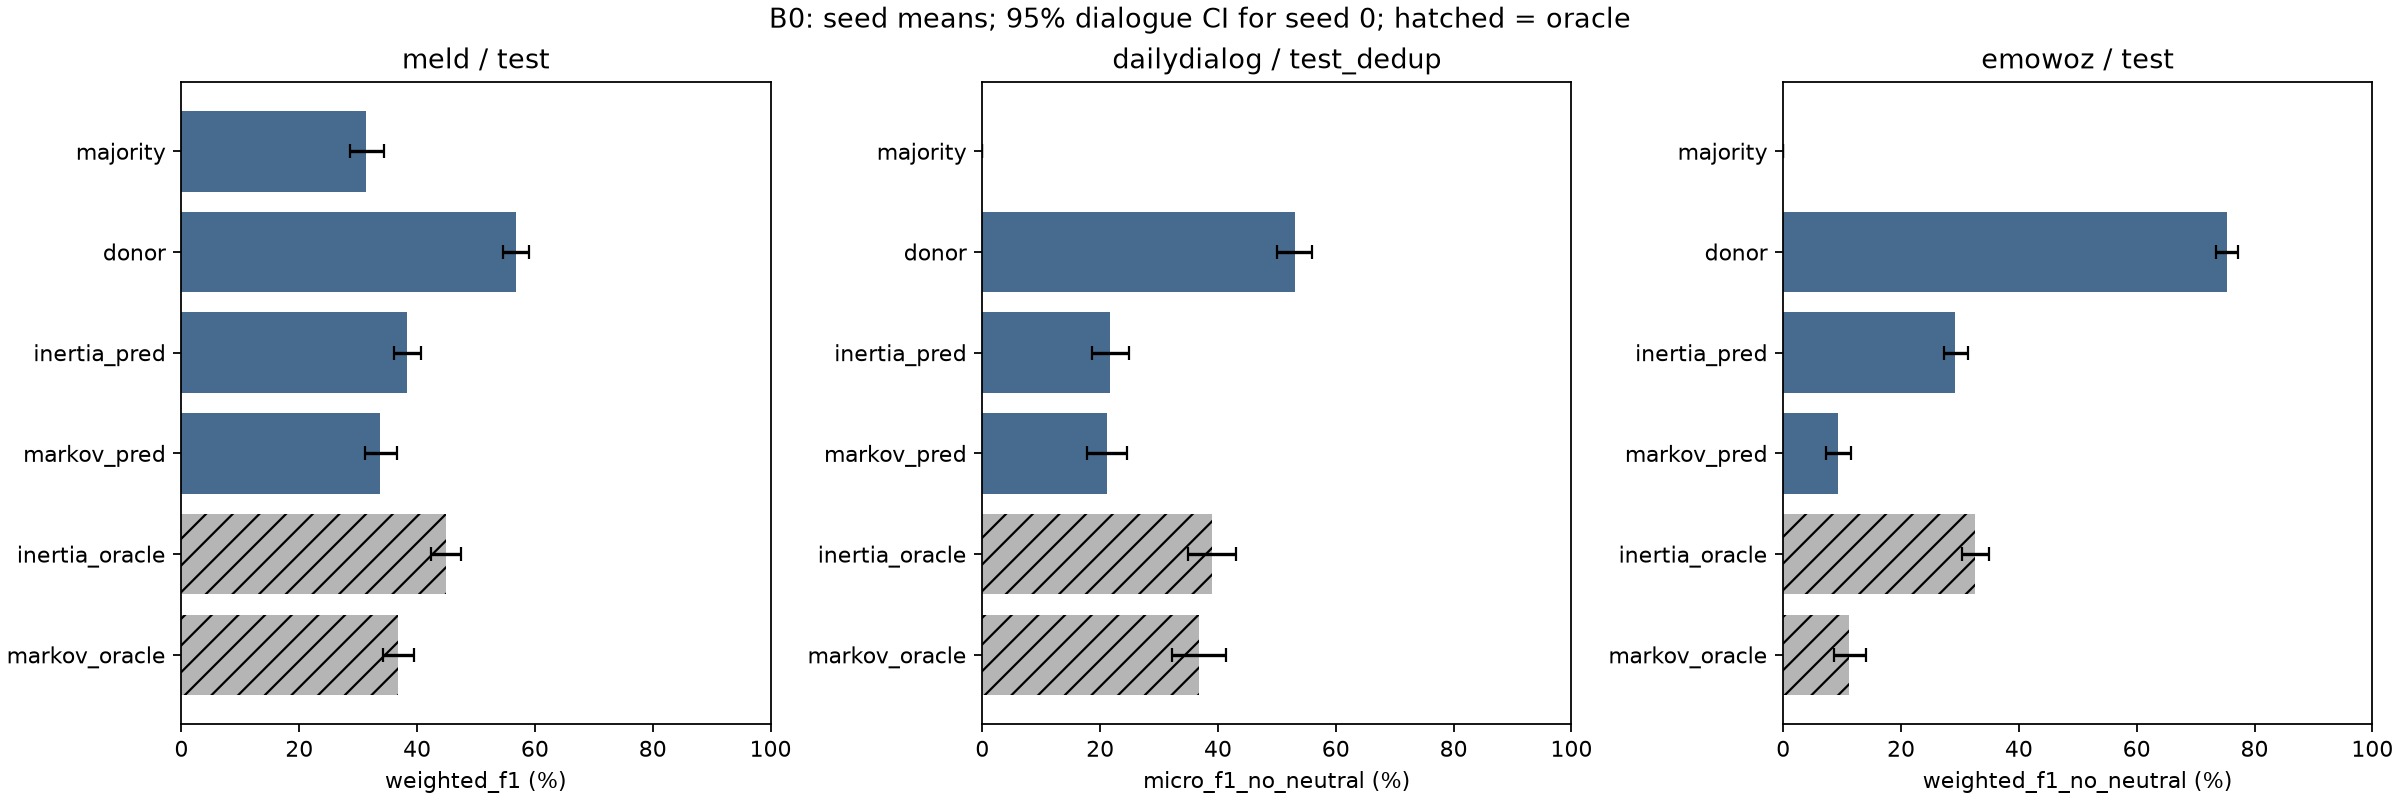

In [6]:
comparison = pd.read_csv('reports/b0/comparison.csv')
display(comparison)
display(Image(filename='reports/b0/figures/headline_comparison.png'))

## Paired differences
Each bootstrap replicate uses the same sampled dialogues for both methods. Delta is candidate minus reference in percentage points, comparing seed-0 checkpoints, not five-seed means. An interval crossing zero does not establish a clear direction. Oracle comparisons are diagnostic. These exploratory post-hoc pointwise intervals have no multiple-comparison correction and do not establish causality.

,dataset,metric,reference,candidate,oracle,diff_pp,ci_low_pp,ci_high_pp,interval_direction
0,meld,weighted_f1,majority,inertia_pred,False,7.035283,5.047071,8.919577,above_zero
1,meld,weighted_f1,inertia_pred,donor,False,18.476949,16.164595,20.732110,above_zero
2,meld,weighted_f1,inertia_pred,markov_pred,False,-4.561672,-6.252570,-2.737695,below_zero
3,meld,weighted_f1,inertia_pred,inertia_oracle,True,6.551335,4.523218,8.778593,above_zero
4,dailydialog,micro_f1_no_neutral,majority,inertia_pred,False,21.682061,18.622245,24.941537,above_zero
5,dailydialog,micro_f1_no_neutral,inertia_pred,donor,False,31.350598,28.135050,34.486898,above_zero
6,dailydialog,micro_f1_no_neutral,inertia_pred,markov_pred,False,-0.473270,-1.919106,0.844882,includes_zero
7,dailydialog,micro_f1_no_neutral,inertia_pred,inertia_oracle,True,17.342329,14.013516,20.641355,above_zero
8,emowoz,weighted_f1_no_neutral,majority,inertia_pred,False,29.238258,27.286575,31.354991,above_zero
9,emowoz,weighted_f1_no_neutral,inertia_pred,donor,False,46.157922,43.506258,48.753995,above_zero


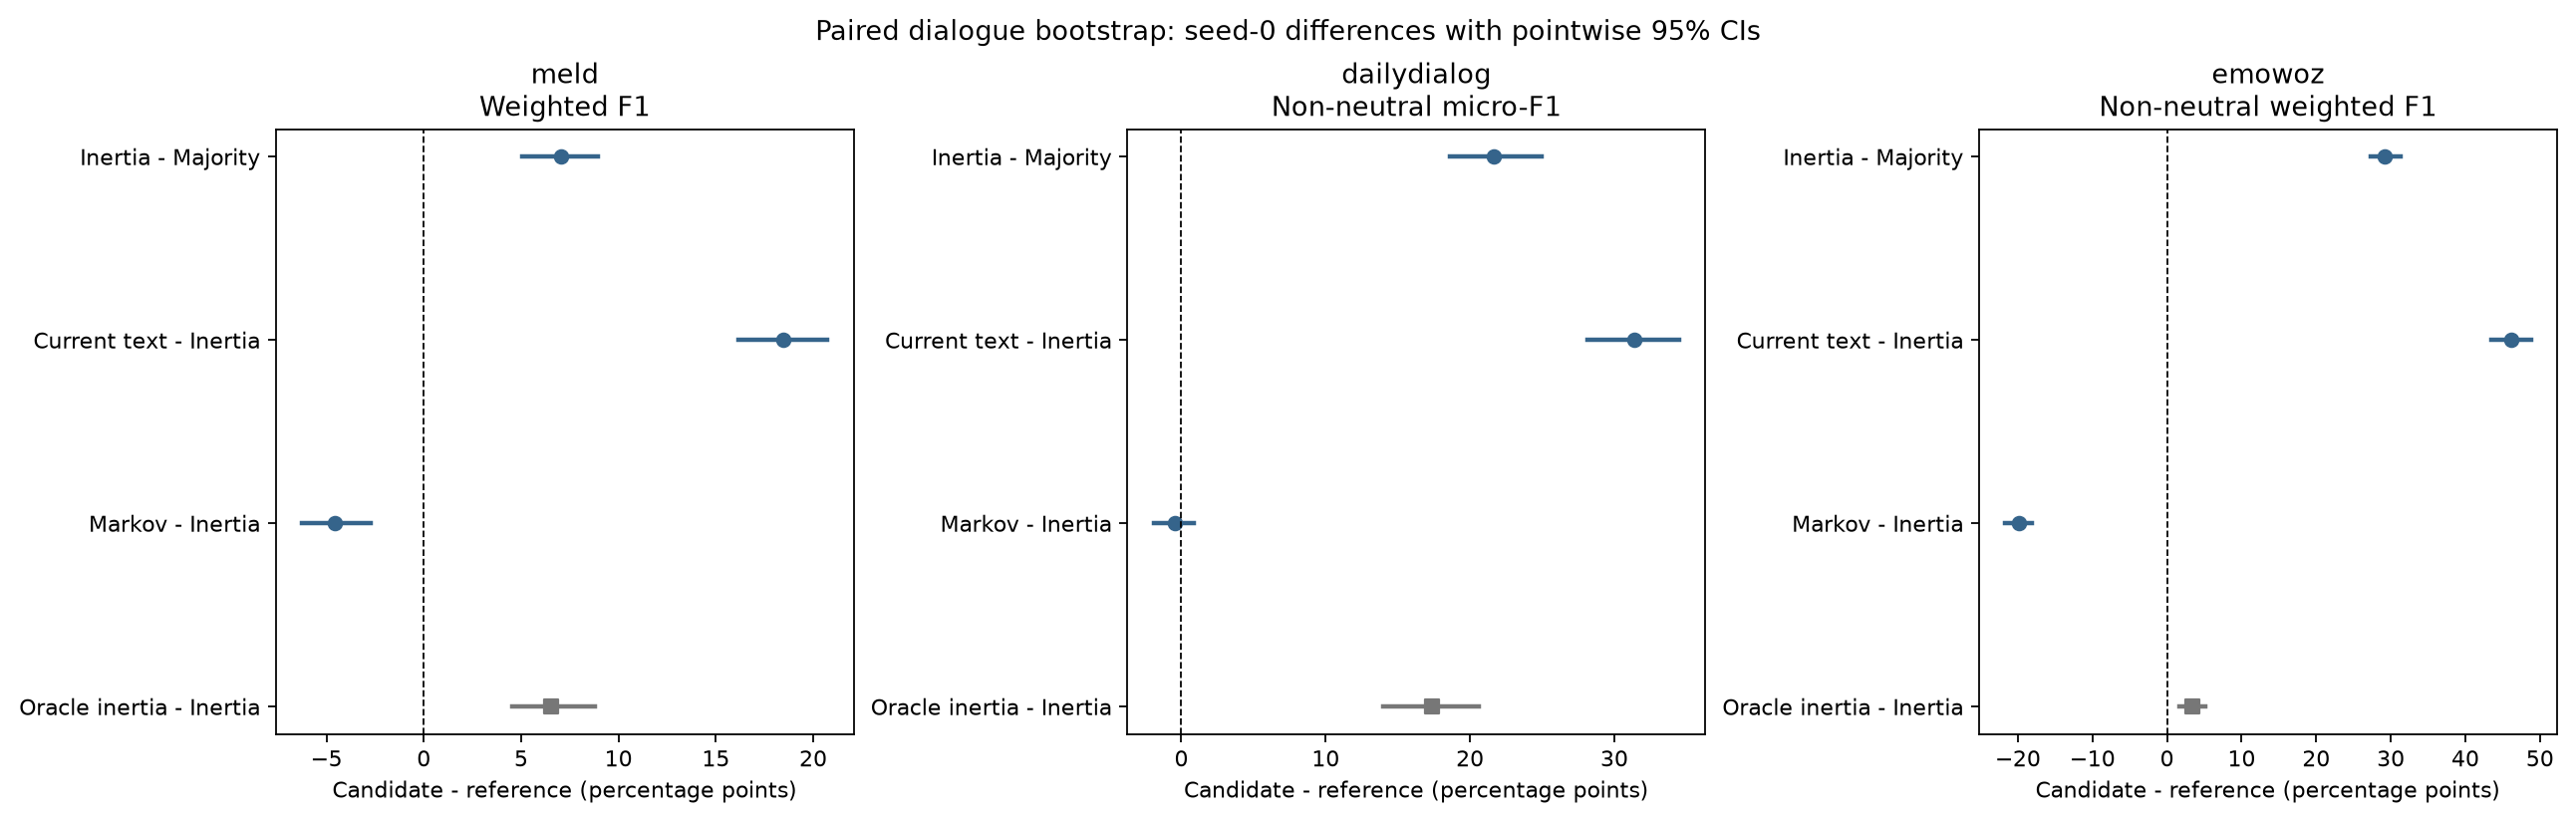

In [7]:
paired = pd.read_csv('reports/b0/paired/headline_differences.csv')
display(paired[['dataset', 'metric', 'reference', 'candidate', 'oracle',
                'diff_pp', 'ci_low_pp', 'ci_high_pp', 'interval_direction']])
display(Image(filename='reports/b0/paired/headline_differences.png'))

## Shift vs stable
Gold shift strata are evaluation metadata only. They are not inference inputs.

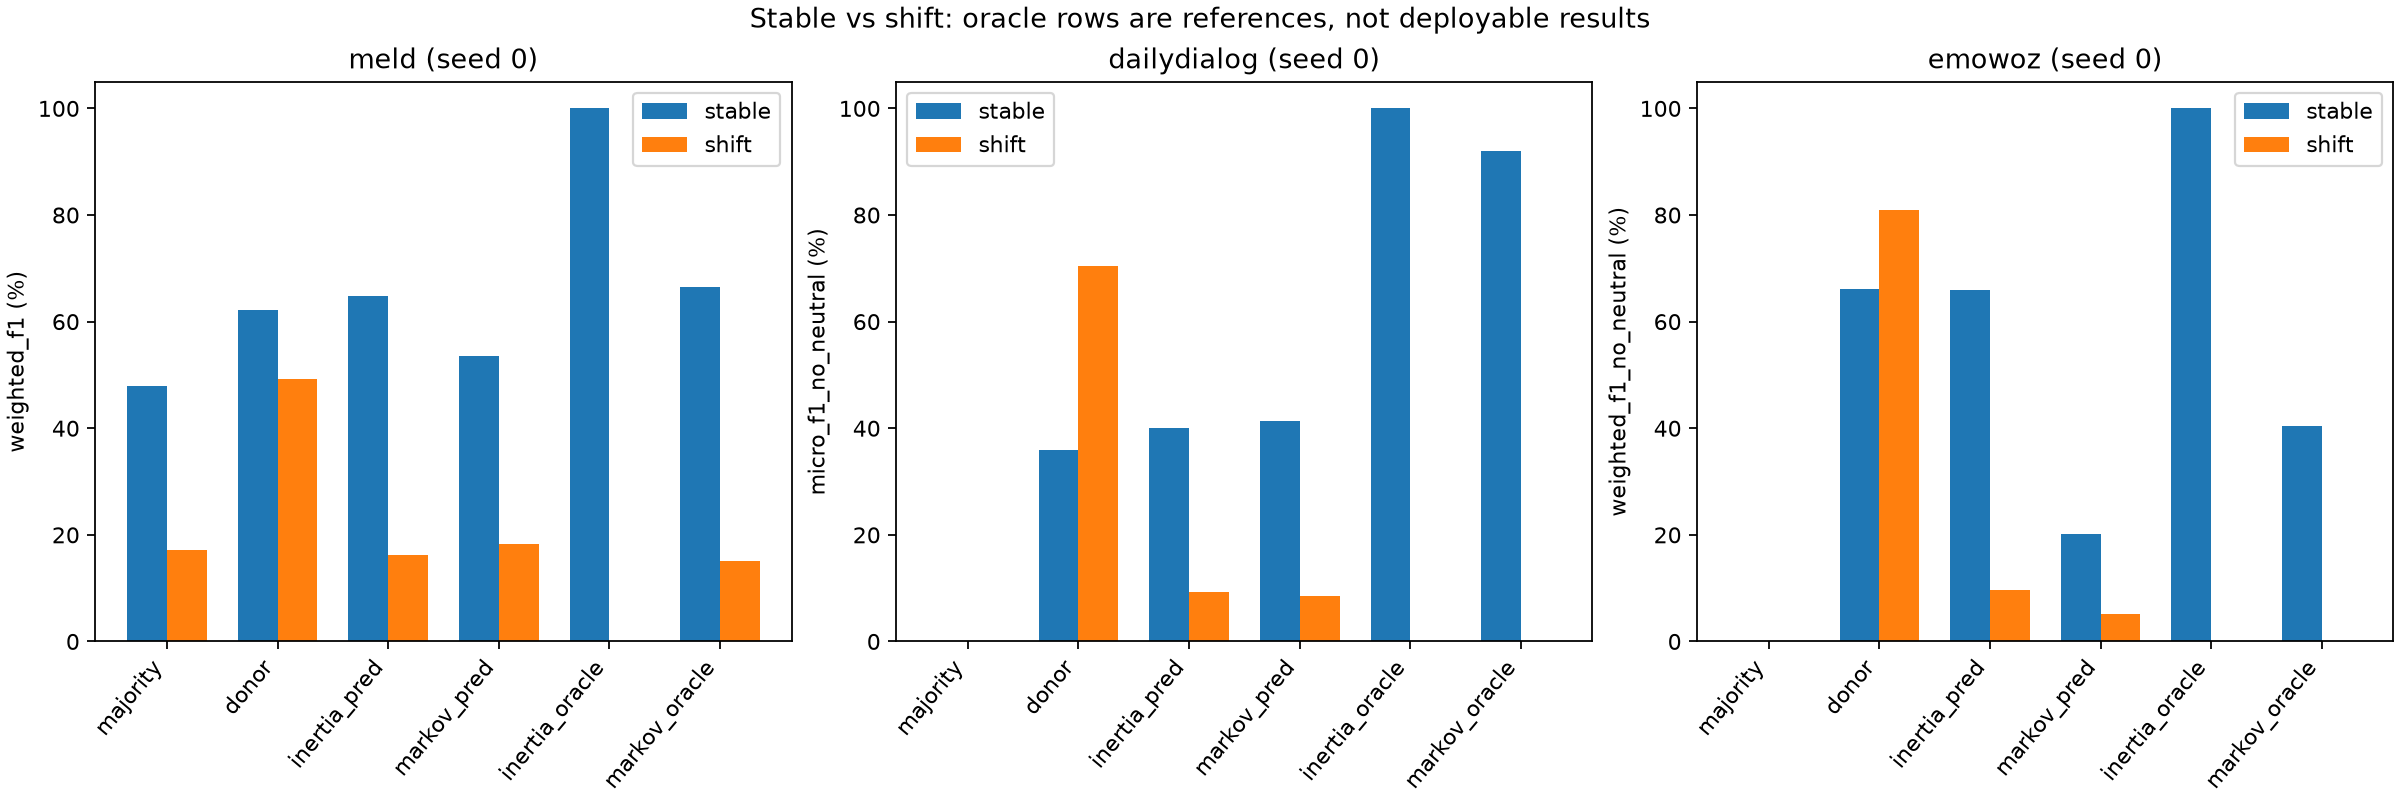

,dataset,model,group,metric,score
0,meld,majority,stable,weighted_f1,0.479146
1,meld,majority,shift,weighted_f1,0.171637
2,meld,donor,stable,weighted_f1,0.621197
3,meld,donor,shift,weighted_f1,0.491475
4,meld,inertia_pred,stable,weighted_f1,0.647777
5,meld,inertia_pred,shift,weighted_f1,0.161728
6,meld,markov_pred,stable,weighted_f1,0.536171
7,meld,markov_pred,shift,weighted_f1,0.183356
8,meld,inertia_oracle,stable,weighted_f1,1.000000
9,meld,inertia_oracle,shift,weighted_f1,0.000000


In [8]:
display(Image(filename='reports/b0/figures/shift_vs_stable.png'))
strata = pd.read_csv('reports/b0/figures/shift_vs_stable.csv')
display(strata)

## Forecasting
Markov shift probabilities are emitted before the current text is read; only non-first user/speaker turns are eligible. Oracle histories are separated. These tables have point estimates, not forecast CIs.

In [9]:
for dataset in ['meld', 'dailydialog', 'emowoz']:
    forecast = pd.read_csv(f'reports/b0/{dataset}/forecast.csv')
    display(forecast[forecast.seed == 0])

,dataset,split,seed,model,n,base_rate,auroc,auprc,brier,scope
0,meld,test,0,markov_pred,1864,0.53809,0.557932,0.569785,0.255356,same-speaker non-first labelled turns; no curr...
1,meld,test,0,markov_oracle,1864,0.53809,0.663302,0.672918,0.226553,same-speaker non-first labelled turns; no curr...


,dataset,split,seed,model,n,base_rate,auroc,auprc,brier,scope
0,dailydialog,test_dedup,0,markov_pred,5237,0.179874,0.588421,0.249861,0.148146,same-speaker non-first labelled turns; no curr...
1,dailydialog,test_dedup,0,markov_oracle,5237,0.179874,0.657809,0.359280,0.127838,same-speaker non-first labelled turns; no curr...
2,dailydialog,test,0,markov_pred,5740,0.179965,0.581336,0.242039,0.150789,same-speaker non-first labelled turns; no curr...
3,dailydialog,test,0,markov_oracle,5740,0.179965,0.656815,0.356175,0.128411,same-speaker non-first labelled turns; no curr...


,dataset,split,seed,model,n,base_rate,auroc,auprc,brier,scope
0,emowoz,test,0,markov_pred,7534,0.351739,0.569285,0.407721,0.228079,same-speaker non-first labelled turns; no curr...
1,emowoz,test,0,markov_oracle,7534,0.351739,0.607909,0.463169,0.210683,same-speaker non-first labelled turns; no curr...


## What did Markov learn?
Rows are the previous labelled emotion of the same speaker; columns are the next/current emotion. Diagonal cells measure persistence; the neutral column measures return to neutral. All probabilities come from train, with row support shown on the heatmaps. Argmax may map multiple history labels to neutral, limiting emotional-class recall. These are population patterns, not current-text understanding. Small-support rows require caution; no cellwise probability intervals are estimated.

,dataset,previous_emotion,train_transition_support,self_probability,to_neutral_probability,argmax_next_emotion,argmax_probability,argmax_matches_inertia,empirical_self_probability
0,meld,neutral,3409,0.587822,0.587822,neutral,0.587822,True,0.587856
1,meld,joy,1235,0.333475,0.407339,neutral,0.407339,False,0.333603
2,meld,surprise,852,0.251021,0.353425,neutral,0.353425,False,0.251174
3,meld,anger,820,0.408174,0.268540,anger,0.408174,True,0.408537
4,meld,sadness,482,0.279645,0.346732,neutral,0.346732,False,0.280083
5,meld,disgust,185,0.215200,0.314363,neutral,0.314363,False,0.216216
6,meld,fear,191,0.172015,0.325372,neutral,0.325372,False,0.172775
7,dailydialog,neutral,55807,0.878258,0.878258,neutral,0.878258,True,0.878259
8,dailydialog,joy,6291,0.603962,0.370920,joy,0.603962,True,0.604038
9,dailydialog,surprise,1264,0.110686,0.716069,neutral,0.716069,False,0.110759


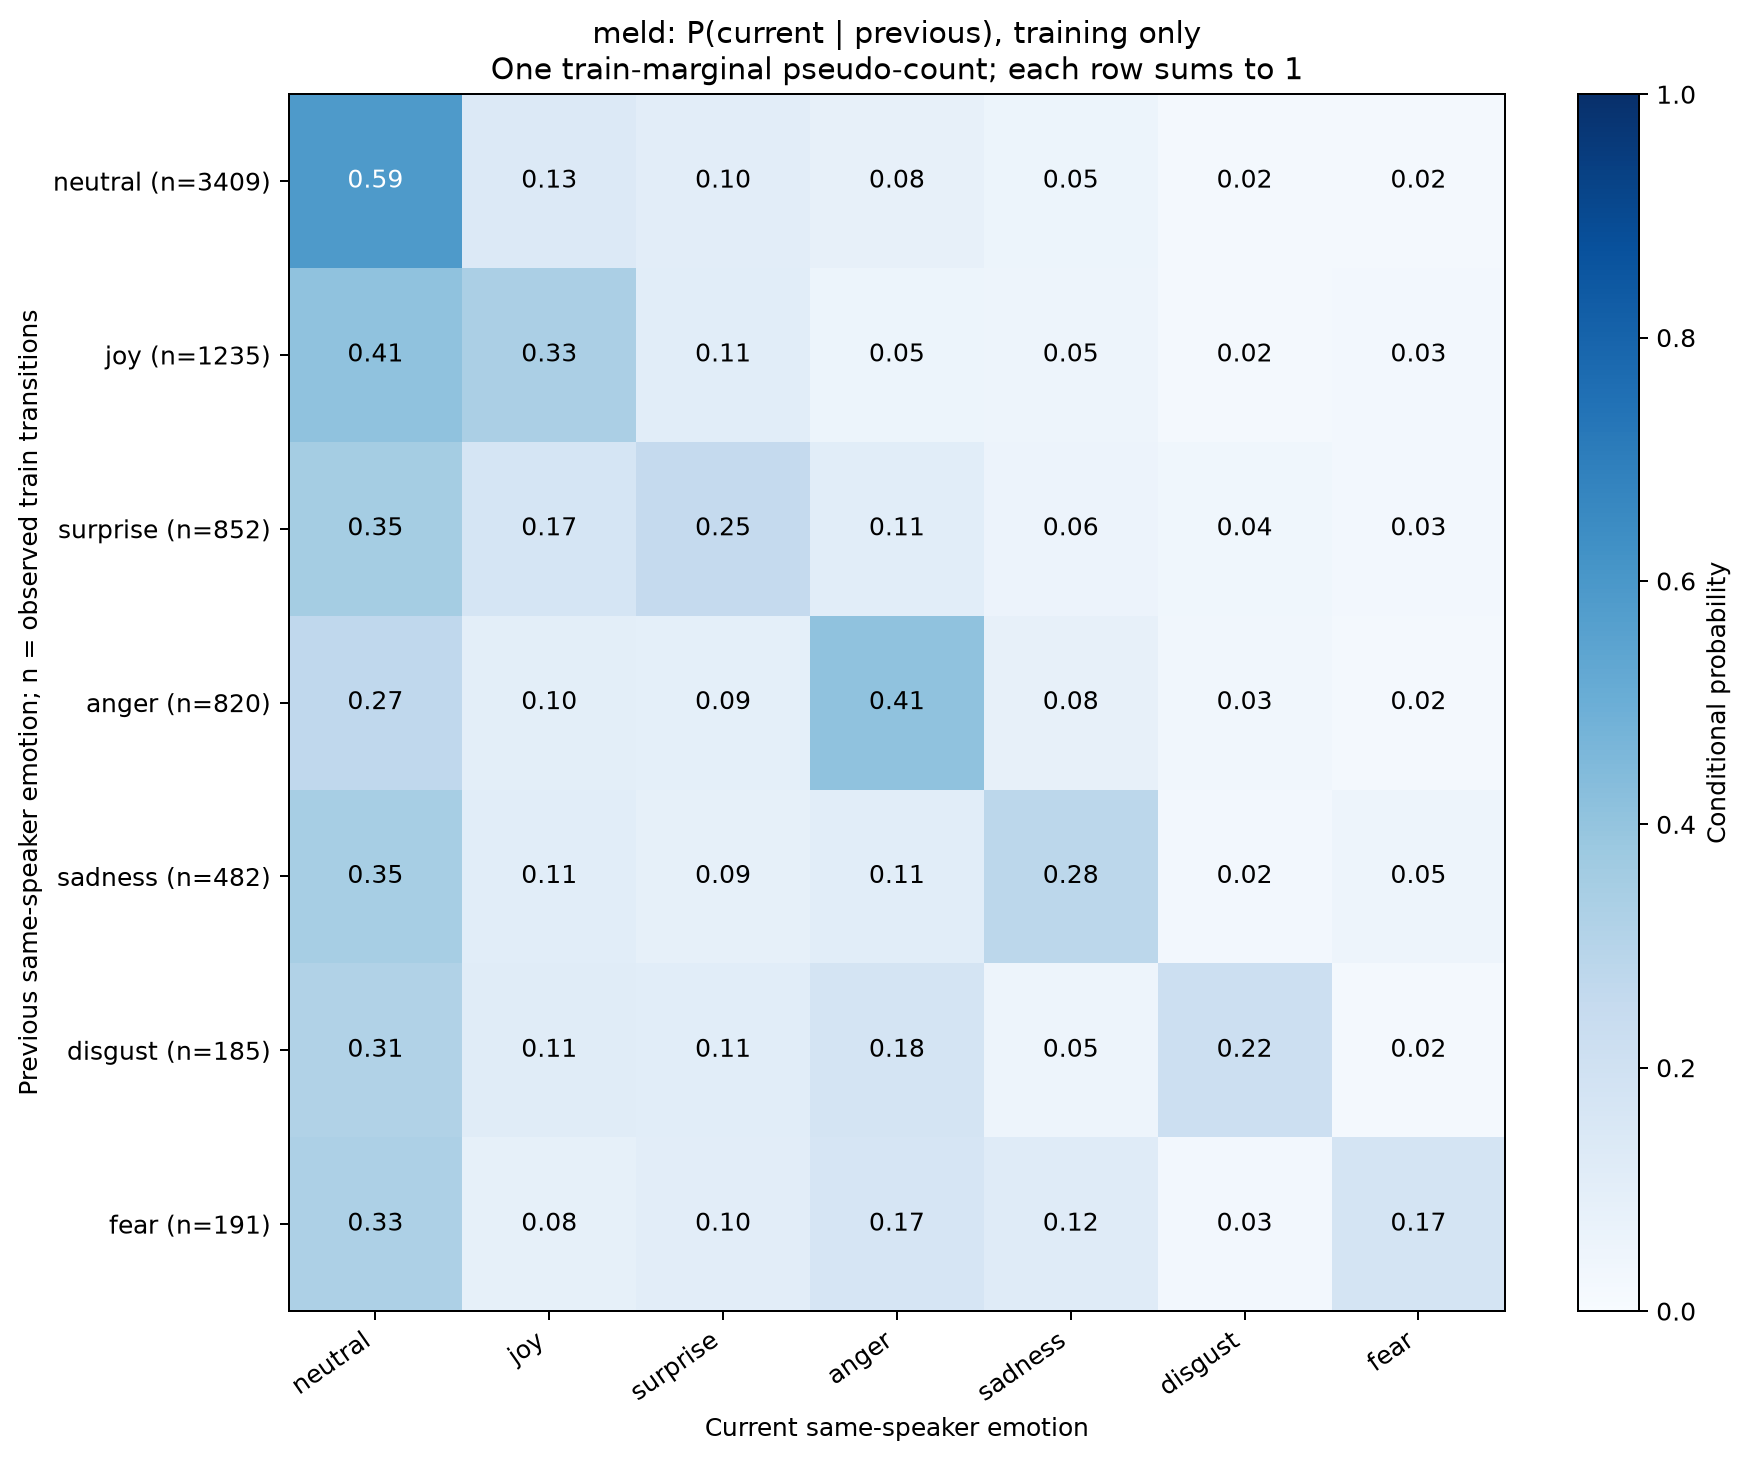

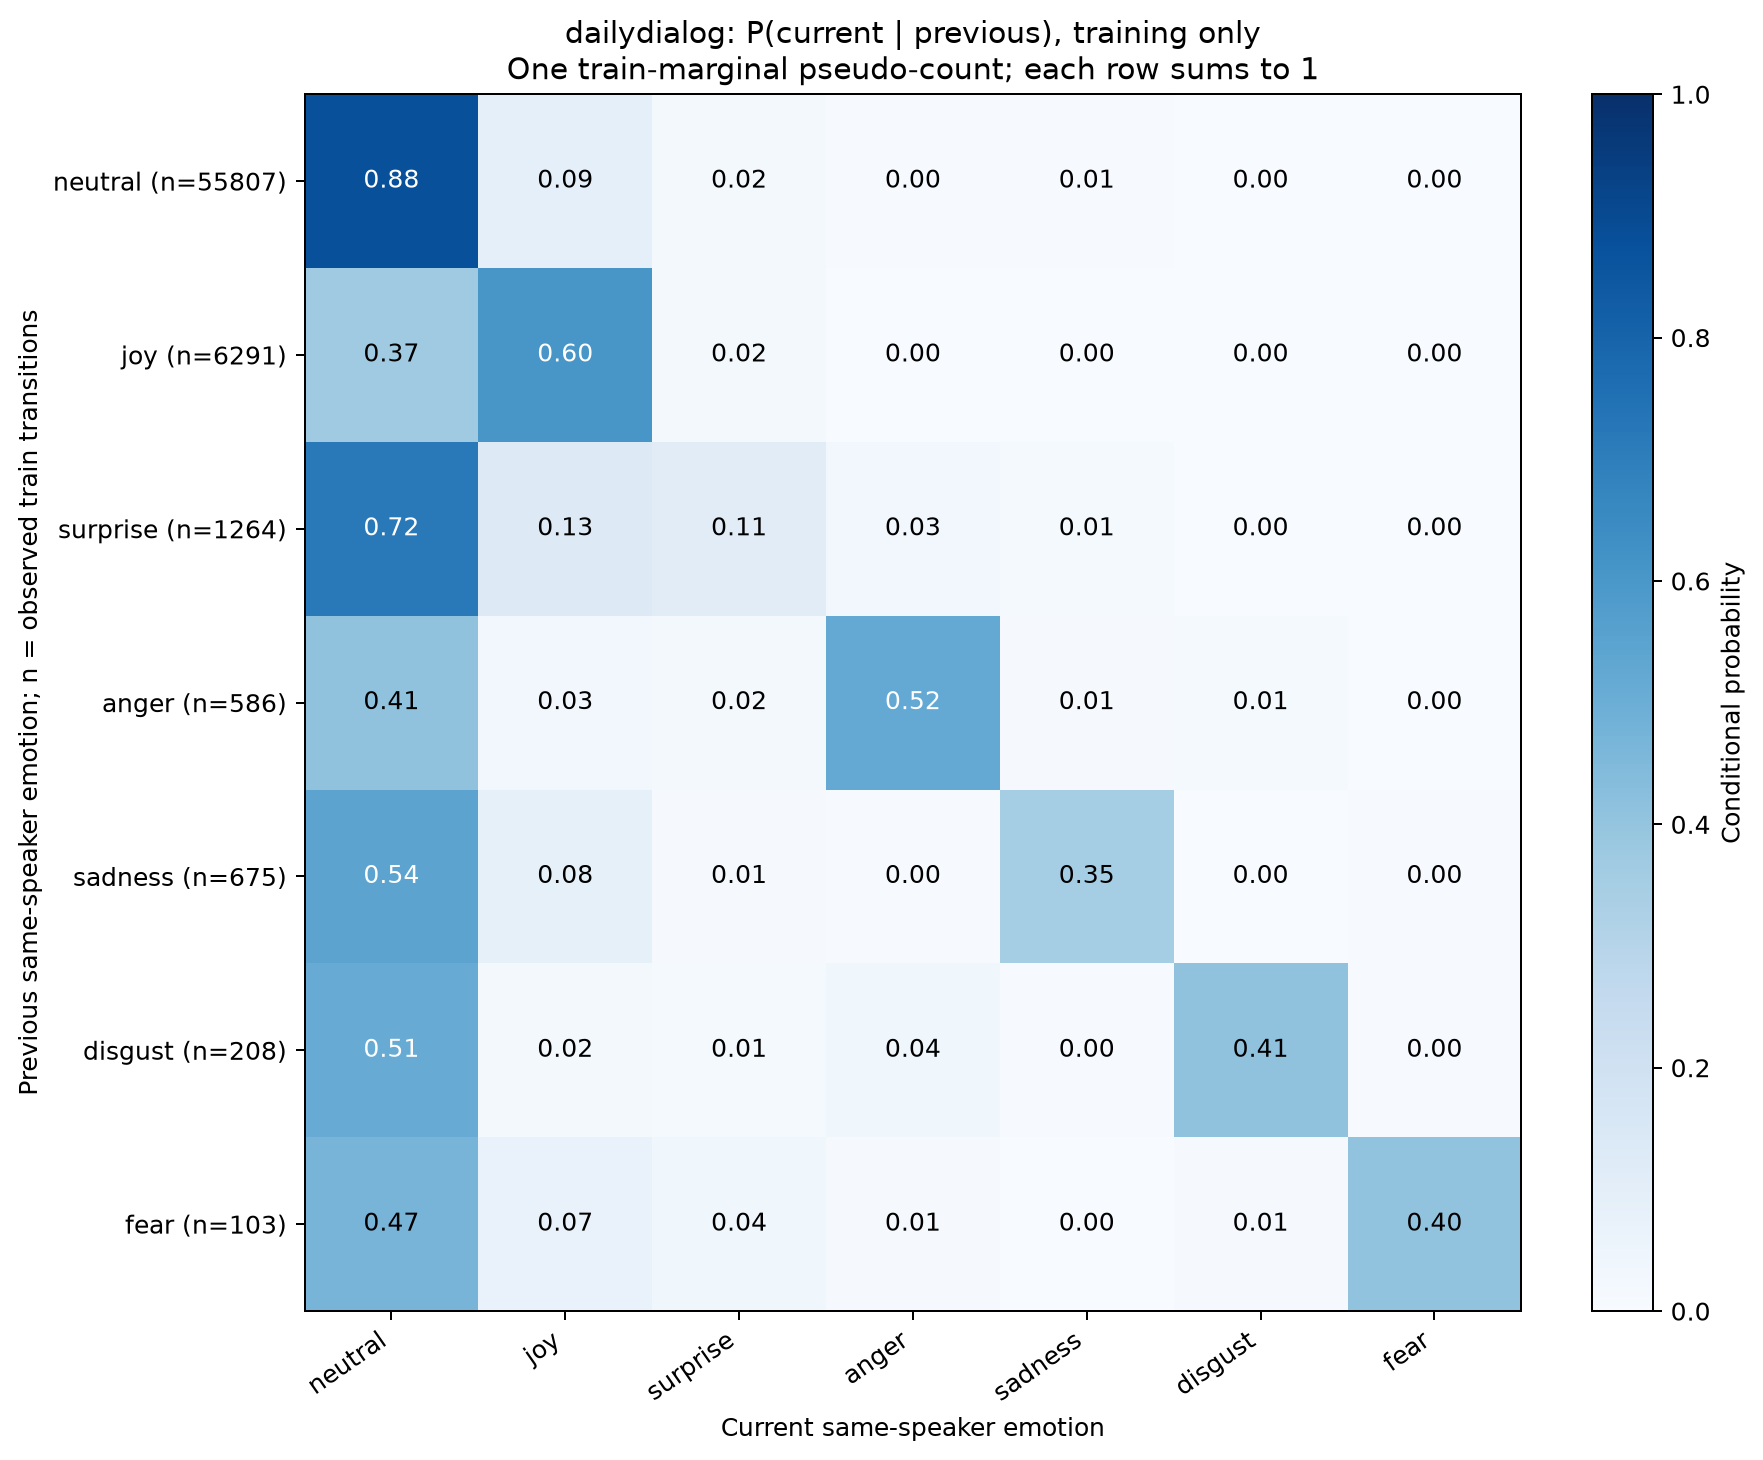

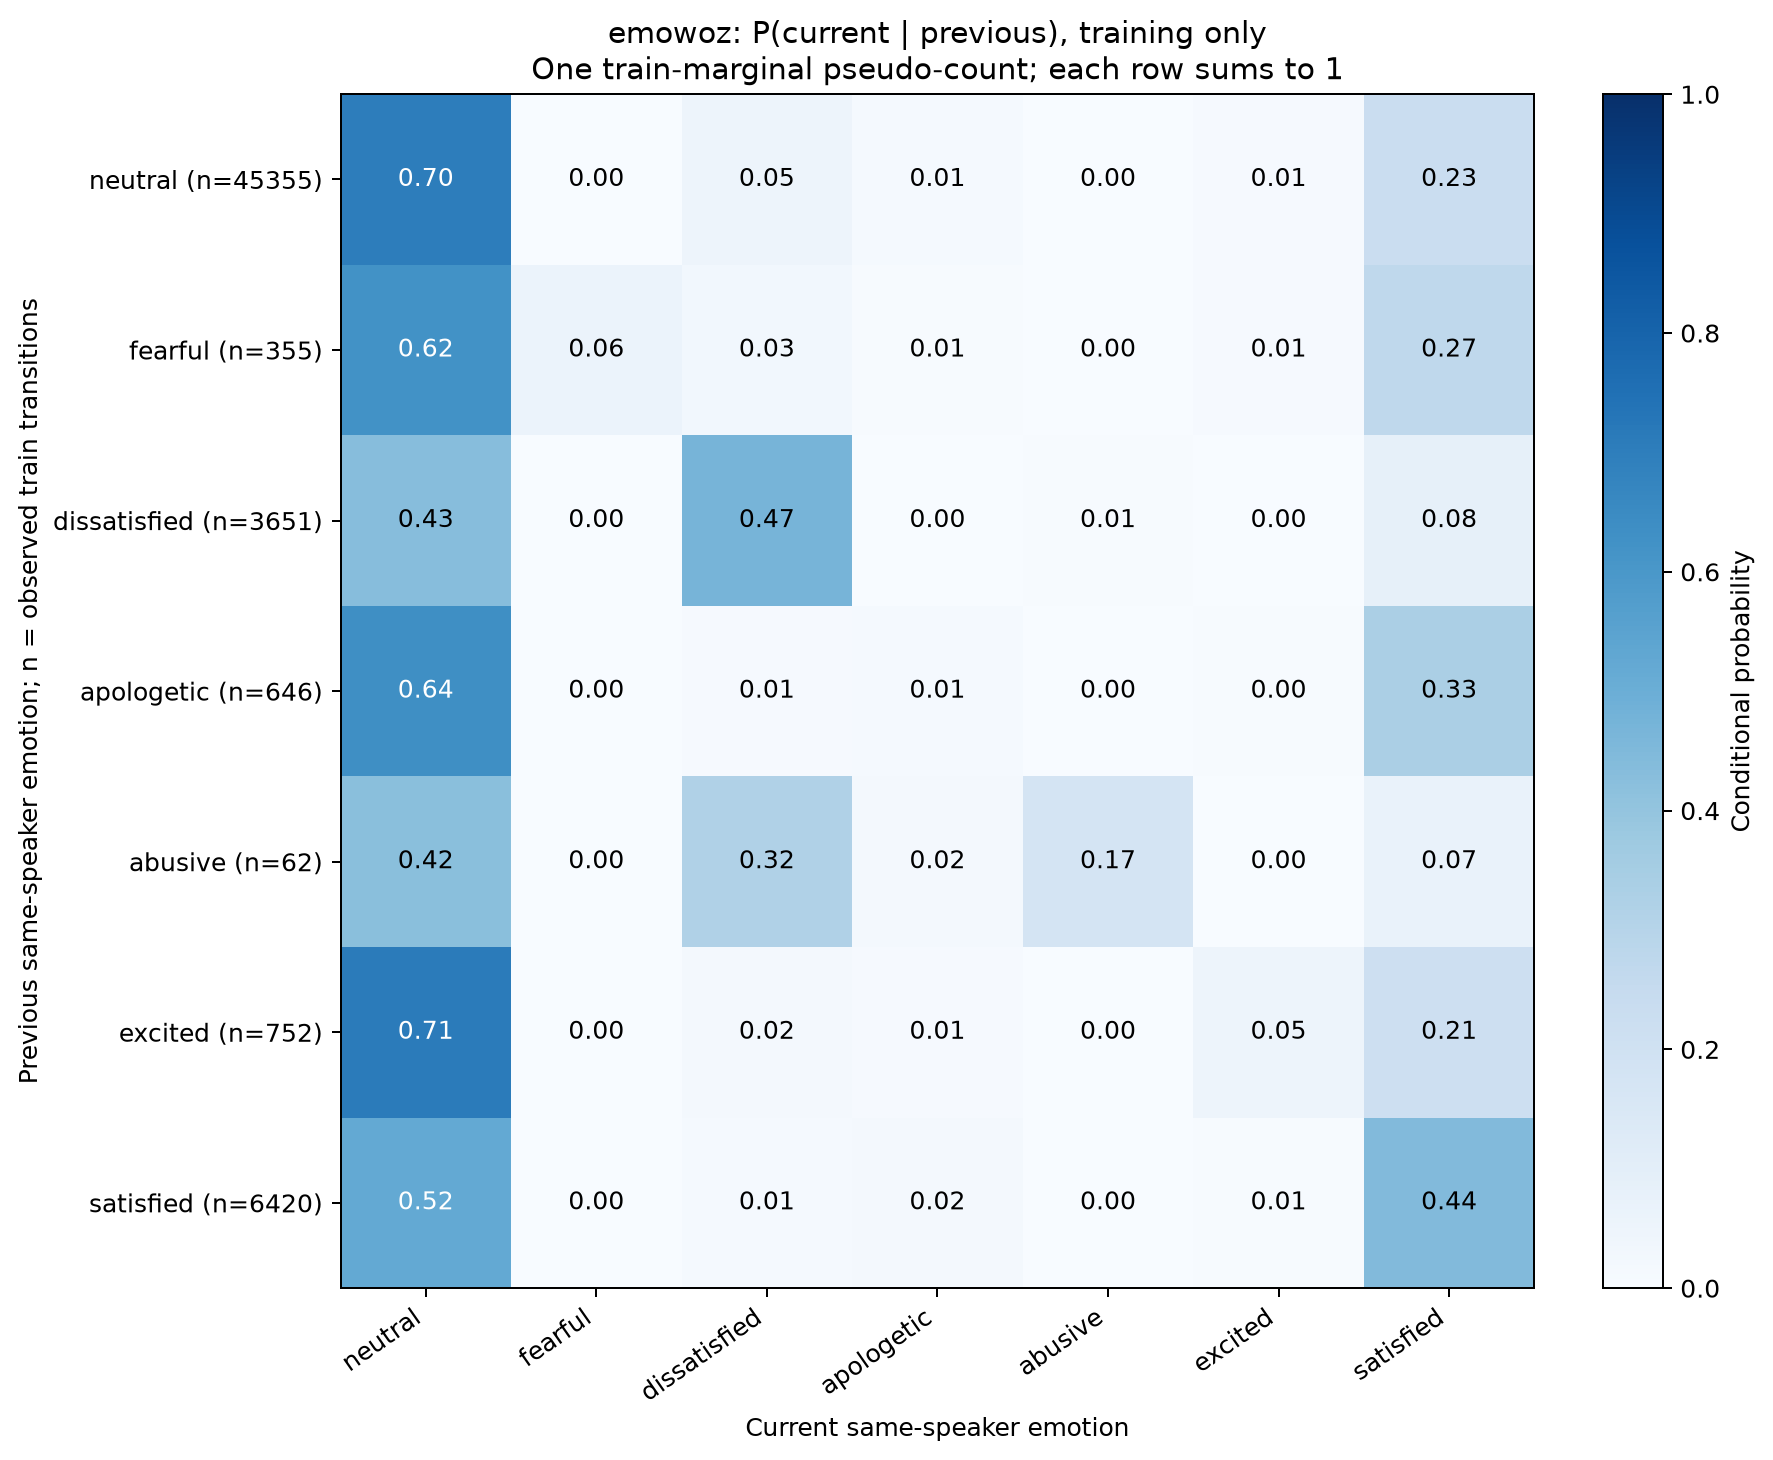

,dataset,split,model,emotion,gold_n,predicted_n,predicted_fraction
21,meld,test,markov_pred,neutral,1256,2454,0.940230
22,meld,test,markov_pred,joy,402,0,0.000000
23,meld,test,markov_pred,surprise,281,0,0.000000
24,meld,test,markov_pred,anger,345,156,0.059770
25,meld,test,markov_pred,sadness,208,0,0.000000
26,meld,test,markov_pred,disgust,68,0,0.000000
27,meld,test,markov_pred,fear,50,0,0.000000
49,dailydialog,test_dedup,markov_pred,neutral,5746,6472,0.922069
50,dailydialog,test_dedup,markov_pred,joy,916,497,0.070808
51,dailydialog,test_dedup,markov_pred,surprise,110,0,0.000000


In [10]:
transition = pd.read_csv('reports/b0/transitions/transition_summary.csv')
display(transition)
for dataset in ['meld', 'dailydialog', 'emowoz']:
    display(Image(filename=f'reports/b0/transitions/{dataset}_transition.png'))
distribution = pd.read_csv('reports/b0/transitions/prediction_distribution.csv')
display(distribution[distribution.model == 'markov_pred'])

## Verification and limits
Run the artifact audit to recompute every stored recognition metric and check row identity. Native EmoWOZ scores are not directly comparable to Ekman-label scores. Neither lagged recognition nor Markov models understand the current text; oracle performance cannot be claimed at deployment.

In [11]:
from scripts.make_b0_artifacts import audit
print('Prediction files verified:', audit())

Prediction files verified: 72


## References and hand-in
See `docs/B0_BASELINES.md` and `deliverables/01_inertia/refs.txt`. The data-loader, donor and metric implementation are shared team work. This work adds B0 rules, experiments, audit and explanation with AI assistance; review the code and disclose usage as required. Use your own voice for narration and the shared slide template.